# Stories Café: How Discounts Change Demand

**Question:** do discounts make people buy more, buy different things, or come back more often, and are they worth what they cost?

The data has two kinds of discount:

| Discount | Where and when | What it looks like |
|---|---|---|
| **10% off** | All branches, every month, every product | A standing discount on about 1 line in 18 |
| **15% off** | Harbour only, Cold Coffee and Desserts, Mar 12-19 and May 12-19 | A short promotion on two categories |

Prices themselves never change within a branch, so the discounts are the only price changes we can learn from.

**Sections**
1. Setup
2. The discount landscape: how much, where, when, and what it costs
3. Who gets the 10% discount?
4. Do discounts make orders bigger?
5. Do discounts change what people buy?
6. Do discounts bring customers back sooner?
7. The 15% promotion: did it lift demand?
8. Can we measure price sensitivity at all?
9. What the discounts cost, and what removing them would be worth
10. Conclusion and recommendations

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates

PROMO_WINDOWS = [("2026-03-12", "2026-03-19"), ("2026-05-12", "2026-05-19")]
PROMO_BRANCH, PROMO_CATEGORIES = "Harbour", ["Cold Coffee", "Desserts"]
REGULAR_RATE, OCCASIONAL_RATE, NEW_DAYS = 1.5, 0.75, 45  # customer segments, as in 04_regular_customers
N_SHUFFLES = 300
rng = np.random.default_rng(490)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
RATE_COLORS = {"No discount": "#b9b8b3", "10% off": "#3987e5", "15% off": "#184f95"}
ACCENT, NEG, MUTED, BAND, PROMO_SHADE = "#2a78d6", "#e34948", "#b9b8b3", "#ecebe6", "#f3d9d3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
pct1 = mtick.PercentFormatter(1.0, decimals=1)
usd = mtick.StrMethodFormatter("${x:,.0f}")
R, GP, D = "Line Revenue (USD)", "Line Gross Profit (USD)", "Discount Rate"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour
df["rate"] = df[D].map({0.0: "No discount", 0.10: "10% off", 0.15: "15% off"})
df["list_revenue"] = df["Quantity"] * df["Unit Price (USD)"]
df["given_away"] = df["list_revenue"] - df[R]
df["lines_in_order"] = df.groupby("Transaction ID")[R].transform("size")
df["in_promo"] = False
for a, b in PROMO_WINDOWS:
    df["in_promo"] |= df["Date"].between(a, b)

# Customer segments (same rules as 04_regular_customers)
orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), branch=("Branch", "first"), customer=("Customer ID", "first"),
    revenue=(R, "sum"), profit=(GP, "sum"), items=("Quantity", "sum"), lines=("Product", "size"),
    any_10=(D, lambda s: (s == 0.10).any()), any_15=(D, lambda s: (s == 0.15).any()))
END = orders["date"].max()
cust = orders.dropna(subset=["customer"]).groupby("customer").agg(n=("revenue", "size"), first=("date", "min"))
cust["days"] = (END - cust["first"]).dt.days + 1
cust["rate"] = cust["n"] / cust["days"] * 30
cust["segment"] = np.select([cust["days"] < NEW_DAYS, cust["rate"] >= REGULAR_RATE, cust["rate"] >= OCCASIONAL_RATE],
                            ["New", "Regular", "Occasional"], "Rare")
df["segment"] = df["Customer ID"].map(cust["segment"]).fillna("Anonymous")
df.groupby("rate").agg(lines=(R, "size"), revenue=(R, "sum"), given_away=("given_away", "sum")).reindex(RATE_COLORS)

,lines,revenue,given_away
rate,,,
No discount,47683,287155.66,0.00
10% off,2860,15360.62,1705.91
15% off,502,2667.43,470.10


## 2. The discount landscape: how much, where, when, and what it costs

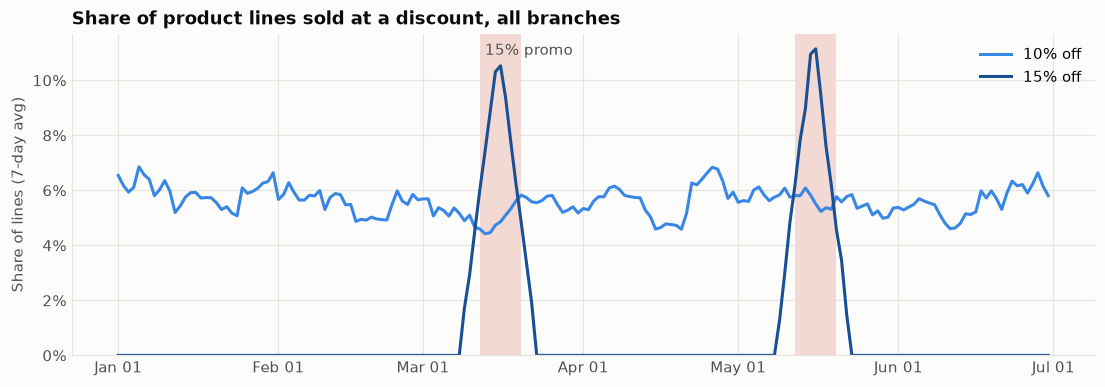

,lines,revenue,profit,given_away,share of lines,gross margin,orders with this discount
rate,,,,,,,
No discount,"47,683","$287,156","$169,040",$0,93.4%,58.9%,
10% off,"2,860","$15,361","$8,351","$1,706",5.6%,54.4%,8.3%
15% off,502,"$2,667","$1,604",$470,1.0%,60.1%,1.4%


In [2]:
summary = df.groupby("rate").agg(lines=(R, "size"), revenue=(R, "sum"), profit=(GP, "sum"),
                                 given_away=("given_away", "sum")).reindex(RATE_COLORS)
summary["share of lines"] = summary["lines"] / summary["lines"].sum()
summary["gross margin"] = summary["profit"] / summary["revenue"]
summary["orders with this discount"] = [np.nan, orders["any_10"].mean(), orders["any_15"].mean()]

daily = df.groupby(["Date", "rate"]).size().unstack().fillna(0)
daily_share = daily.div(daily.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
for a, b in PROMO_WINDOWS:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=PROMO_SHADE, lw=0)
ax.text(pd.Timestamp(PROMO_WINDOWS[0][0]), 0.97, " 15% promo", transform=ax.get_xaxis_transform(), color=INK2, va="top")
for r_ in ["10% off", "15% off"]:
    ax.plot(daily_share.index, daily_share[r_].rolling(7, center=True, min_periods=1).mean(), color=RATE_COLORS[r_], label=r_)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0)
ax.set_ylabel("Share of lines (7-day avg)")
ax.set_title("Share of product lines sold at a discount, all branches")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper right")
plt.show()

summary.style.format({"lines": "{:,.0f}", "revenue": "${:,.0f}", "profit": "${:,.0f}", "given_away": "${:,.0f}",
                      "share of lines": "{:.1%}", "gross margin": "{:.1%}", "orders with this discount": "{:.1%}"},
                     na_rep="")

In [3]:
by_branch = df.groupby("Branch").agg(
    lines_10=(D, lambda s: (s == 0.10).mean()), lines_15=(D, lambda s: (s == 0.15).mean()),
    given_away=("given_away", "sum"), revenue=(R, "sum")).loc[BRANCHES]
by_branch["given away as % of revenue"] = by_branch["given_away"] / by_branch["revenue"]
by_branch.rename(columns={"lines_10": "lines at 10% off", "lines_15": "lines at 15% off"}).drop(columns="revenue").style.format(
    {"lines at 10% off": "{:.1%}", "lines at 15% off": "{:.1%}", "given_away": "${:,.0f}",
     "given away as % of revenue": "{:.2%}"})

,lines at 10% off,lines at 15% off,given_away,given away as % of revenue
Branch,,,,
Harbour,5.6%,2.0%,"$1,298",0.86%
Garden,5.5%,0.0%,$556,0.56%
Uptown,5.8%,0.0%,$322,0.58%


**Takeaway**
- **About 6% of product lines get 10% off**, steadily every day at every branch. That's about 8% of orders: orders with more lines have more chances to include a discounted line (more on that in section 4).
- **15% off** only appears at Harbour in the two promo weeks, where every Cold Coffee and Dessert line got it.
- Together the discounts gave away about **$2,200 of revenue in six months**, about 0.7% of sales. That's small, which matters for the conclusion: discounts are not a big cost, but they also need to earn their keep.

## 3. Who gets the 10% discount?

If the 10% discount were a targeted offer (a loyalty reward, a happy hour, a staff discount, a slow-product push), it would show up more in some places than others. The charts compare the share of lines at 10% off across every dimension we have. The dashed line is the overall rate.

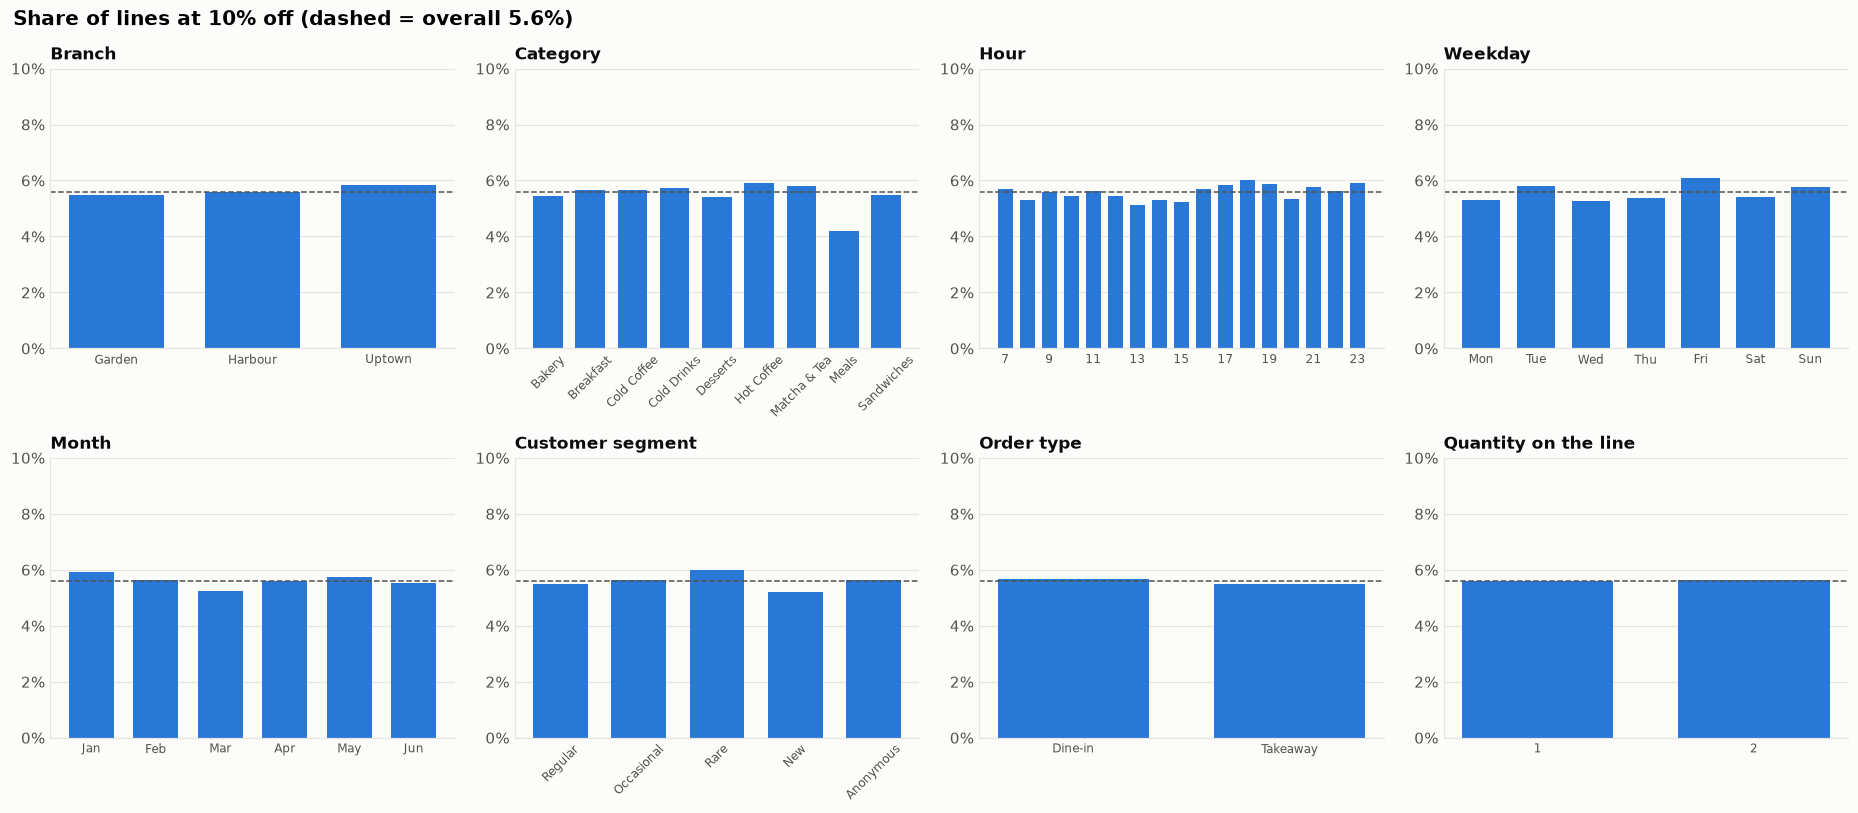

In [4]:
is10 = df[D].eq(0.10)
dims = {
    "Branch": df["Branch"],
    "Category": df["Category"],
    "Hour": df["hour"],
    "Weekday": df["Date"].dt.day_name().str[:3],
    "Month": df["Date"].dt.strftime("%b"),
    "Customer segment": df["segment"],
    "Order type": df["Order Type"],
    "Quantity on the line": df["Quantity"].astype(str),
}
orders_of = {"Weekday": ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
             "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
             "Customer segment": ["Regular", "Occasional", "Rare", "New", "Anonymous"]}
overall = is10.mean()

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, (name, col) in zip(axes.flat, dims.items()):
    s = is10.groupby(col).mean()
    if name in orders_of:
        s = s.reindex(orders_of[name])
    ax.bar(s.index.astype(str), s.values, color=ACCENT, width=0.7)
    ax.axhline(overall, color=INK2, ls="--", lw=1)
    ax.set_ylim(0, 0.1)
    ax.yaxis.set_major_formatter(pct)
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis="x", labelsize=8, rotation=45 if name in ("Category", "Customer segment") else 0)
    if name == "Hour":
        ax.set_xticks(range(0, len(s), 2), s.index[::2].astype(str))
    ax.grid(axis="x", visible=False)
fig.suptitle(f"Share of lines at 10% off (dashed = overall {overall:.1%})", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

In [5]:
# Do some customers get the discount far more often than chance? Compare the spread of per-customer
# discount rates with what you'd get if the same discounted lines were handed out at random.
known = df[df["Customer ID"].notna()]
actual_sd = known.groupby("Customer ID")[D].apply(lambda s: (s == 0.10).mean()).std()
shuffled_sd = []
for _ in range(N_SHUFFLES):
    perm = rng.permutation(known[D].eq(0.10).values)
    shuffled_sd.append(pd.Series(perm, index=known.index).groupby(known["Customer ID"]).mean().std())
lo, hi = np.percentile(shuffled_sd, [2.5, 97.5])
print(f"Spread of per-customer discount rates: actual {actual_sd:.4f}; random hand-out gives {lo:.4f} to {hi:.4f}")
print("Verdict:", "consistent with random" if lo <= actual_sd <= hi else "NOT random: some customers get it more")

Spread of per-customer discount rates: actual 0.0862; random hand-out gives 0.0819 to 0.0908
Verdict: consistent with random


**Takeaway:** the 10% discount lands on **about 5.6% of lines everywhere**: every branch, category, hour, weekday and month, regulars and anonymous walk-ins, dine-in and takeaway, single and double quantities. The spread across customers is exactly what you'd get by handing it out at random.

So the discount isn't targeted at anyone or anything. It isn't a loyalty reward, a happy hour or a slow-product push. In a real café this pattern would point to something like staff discretion or a generic coupon. It also means we can treat the 10% discount as a **natural experiment**: since it's random, any difference in behavior between discounted and full-price purchases would be caused by the discount.

## 4. Do discounts make orders bigger?

At first glance, yes: orders with a discount are bigger. But there's a trap.

In [6]:
naive = orders.assign(has_discount=orders["any_10"] | orders["any_15"]).groupby("has_discount").agg(
    orders=("revenue", "size"), avg_lines=("lines", "mean"), avg_items=("items", "mean"), avg_value=("revenue", "mean"))
naive.index = ["No discount", "At least one discounted line"]
naive.style.format({"orders": "{:,.0f}", "avg_lines": "{:.2f}", "avg_items": "{:.2f}", "avg_value": "${:.2f}"})

,orders,avg_lines,avg_items,avg_value
No discount,"30,640",1.49,1.57,$8.94
At least one discounted line,"3,247",1.71,1.81,$9.60


**The trap:** the discount is applied to individual lines, not to whole orders. An order with three lines has three chances of getting a discounted line, so **bigger orders are more likely to contain a discount, even if the discount had no effect at all**. The fair test is at the line level: is a line more likely to be discounted when it's part of a bigger order, and do discounted lines have bigger quantities?

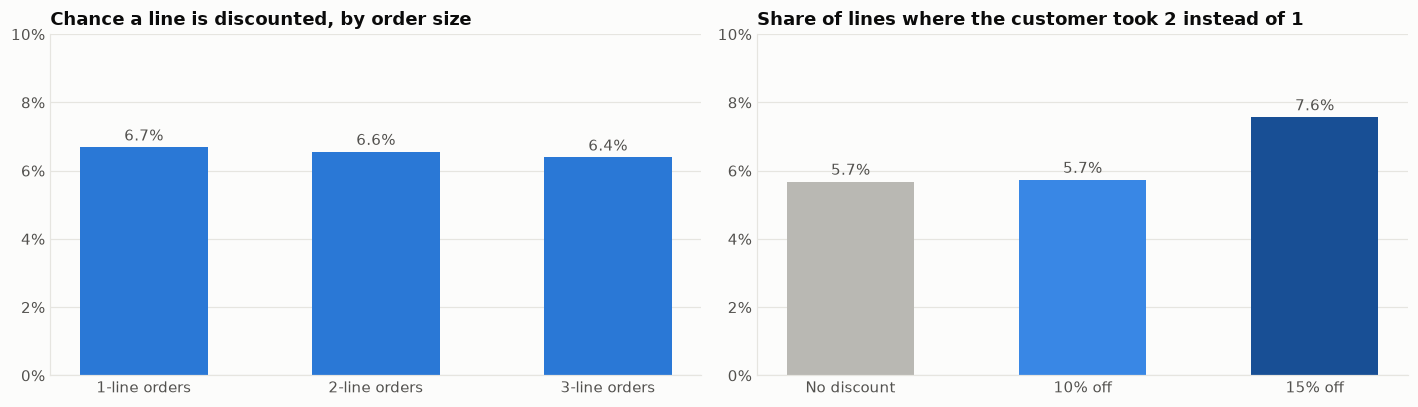

,avg_quantity,share_with_qty_2
rate,,
No discount,1.057,5.7%
10% off,1.057,5.7%
15% off,1.076,7.6%


In [7]:
line_test = pd.DataFrame({
    "share of lines discounted": df.groupby("lines_in_order")[D].apply(lambda s: (s > 0).mean()),
    "lines": df.groupby("lines_in_order").size(),
})
line_test.index = [f"{n}-line orders" for n in line_test.index]
qty_test = df.groupby("rate")["Quantity"].agg(avg_quantity="mean", share_with_qty_2=lambda s: (s == 2).mean()).reindex(RATE_COLORS)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ax = axes[0]
ax.bar(line_test.index, line_test["share of lines discounted"], color=ACCENT, width=0.55)
for i, v in enumerate(line_test["share of lines discounted"]):
    ax.text(i, v + 0.002, f"{v:.1%}", ha="center", color=INK2)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.1)
ax.set_title("Chance a line is discounted, by order size")
ax.grid(axis="x", visible=False)
ax = axes[1]
ax.bar(qty_test.index, qty_test["share_with_qty_2"], color=[RATE_COLORS[r_] for r_ in qty_test.index], width=0.55)
for i, v in enumerate(qty_test["share_with_qty_2"]):
    ax.text(i, v + 0.002, f"{v:.1%}", ha="center", color=INK2)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.1)
ax.set_title("Share of lines where the customer took 2 instead of 1")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
qty_test.style.format({"avg_quantity": "{:.3f}", "share_with_qty_2": "{:.1%}"})

**Takeaway:** the bigger discounted orders are **entirely the trap**. A line is equally likely to be discounted whether it's in a 1-, 2- or 3-line order (about 6.5% each), and discounted lines aren't bought in bigger quantities (about 5.6% of lines are a double, with or without the 10% discount). **The 10% discount doesn't make anyone buy more.** The 15% promo lines show a slightly higher double rate (7.6% vs 5.7%), but that's only 502 lines in two categories at one branch, so it's a hint at most.

## 5. Do discounts change what people buy?

If the discount steered choices, discounted lines would lean toward particular products, for example pricier items that feel like a better deal.

In [8]:
mix = pd.crosstab(df["Category"], df["rate"], values=df["Quantity"], aggfunc="sum", normalize="columns")[["No discount", "10% off"]]
mix["difference (points)"] = (mix["10% off"] - mix["No discount"]) * 100
price = df.groupby("rate")["Unit Price (USD)"].mean().reindex(RATE_COLORS)
print("Average list price of the item: " + ", ".join(f"{k} ${v:.2f}" for k, v in price.items()))
mix.sort_values("No discount", ascending=False).style.format("{:.1%}").format("{:+.1f}", subset=["difference (points)"])

Average list price of the item: No discount $5.69, 10% off $5.65, 15% off $5.80


rate,No discount,10% off,difference (points)
Category,,,
Bakery,21.8%,21.2%,-0.6
Hot Coffee,16.0%,16.6%,+0.6
Matcha & Tea,14.9%,15.2%,+0.3
Cold Coffee,13.8%,14.6%,+0.9
Cold Drinks,10.3%,10.3%,+0.0
Desserts,8.4%,8.4%,-0.0
Sandwiches,7.3%,7.1%,-0.2
Breakfast,4.6%,4.6%,+0.0
Meals,2.9%,2.0%,-0.9


**Takeaway:** discounted and full-price lines have almost the same category mix (every category within about 1 point) and the same average list price ($5.65 vs $5.69). People don't pick different or pricier products when they get the discount.

## 6. Do discounts bring customers back sooner?

A discount can pay for itself if it makes a customer come back sooner or more often. For identified customers we compare **the time until their next visit** after an order that had a discounted line vs an order that didn't. To keep it fair, we only use orders at least 30 days before the end of the data, and we also compare **within the same customer** (their own discounted vs full-price visits), so heavy and light visitors don't skew it.

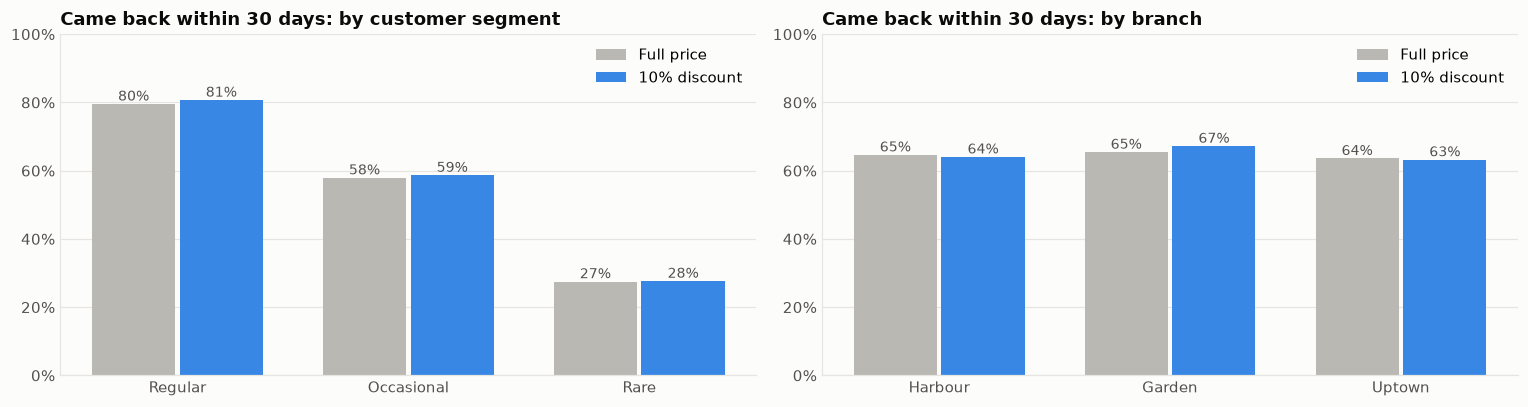

,orders,back_within_30_days,median_days_to_next,days_vs_own_average
discounted,,,,
10% discount,"1,413",64.9%,20,-0.3
No discount,"15,709",64.7%,19,+0.0


In [9]:
k = orders.dropna(subset=["customer"]).sort_values(["customer", "date"]).copy()
k["next_visit_days"] = (k.groupby("customer")["date"].shift(-1) - k["date"]).dt.days
k = k[k["date"] <= END - pd.Timedelta(days=30)]
k["back_within_30"] = k["next_visit_days"].le(30)
k["segment"] = k["customer"].map(cust["segment"])
k["discounted"] = np.where(k["any_10"], "10% discount", "No discount")
k["gap_vs_own_average"] = k["next_visit_days"] - k.groupby("customer")["next_visit_days"].transform("mean")

ret = k.groupby("discounted").agg(orders=("revenue", "size"), back_within_30_days=("back_within_30", "mean"),
                                  median_days_to_next=("next_visit_days", "median"),
                                  days_vs_own_average=("gap_vs_own_average", "mean"))
by_seg = k.groupby(["segment", "discounted"])["back_within_30"].mean().unstack()
by_br = k.groupby(["branch", "discounted"])["back_within_30"].mean().unstack().loc[BRANCHES]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, t, title in [(axes[0], by_seg.reindex(["Regular", "Occasional", "Rare"]), "By customer segment"),
                     (axes[1], by_br, "By branch")]:
    x = np.arange(len(t))
    ax.bar(x - 0.19, t["No discount"], width=0.36, color=RATE_COLORS["No discount"], label="Full price")
    ax.bar(x + 0.19, t["10% discount"], width=0.36, color=RATE_COLORS["10% off"], label="10% discount")
    for xi, (a, b) in enumerate(t[["No discount", "10% discount"]].values):
        ax.text(xi - 0.19, a + 0.01, f"{a:.0%}", ha="center", color=INK2, fontsize=9)
        ax.text(xi + 0.19, b + 0.01, f"{b:.0%}", ha="center", color=INK2, fontsize=9)
    ax.set_xticks(x, t.index)
    ax.yaxis.set_major_formatter(pct)
    ax.set_ylim(0, 1)
    ax.set_title(f"Came back within 30 days: {title.lower()}")
    ax.legend(loc="upper right")
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
ret.style.format({"orders": "{:,.0f}", "back_within_30_days": "{:.1%}", "median_days_to_next": "{:.0f}",
                  "days_vs_own_average": "{:+.1f}"})

**Takeaway:** customers who got a discount **came back just as often and just as soon** as after a full-price visit: about 65% within 30 days either way, with a median of 19-20 days to the next visit. Within the same customer, a discounted visit is followed by the next visit only about a third of a day sooner than their own average, which is nothing. The same holds for regulars, occasional and rare customers, and at every branch. **The discount doesn't build loyalty.**

## 7. The 15% promotion: did it lift demand?

The 15% promo is the closest thing to a real price test: Harbour cut Cold Coffee and Dessert prices by 15% for two 8-day windows. If customers respond to price, Harbour should sell **more** Cold Coffee and Desserts during those days, compared with:
- the same Harbour categories on other days (before vs during), and
- Garden and Uptown, which had no promo on those days (the control branches).

This comparison of the change at Harbour against the change at the control branches is called a **difference-in-differences**.

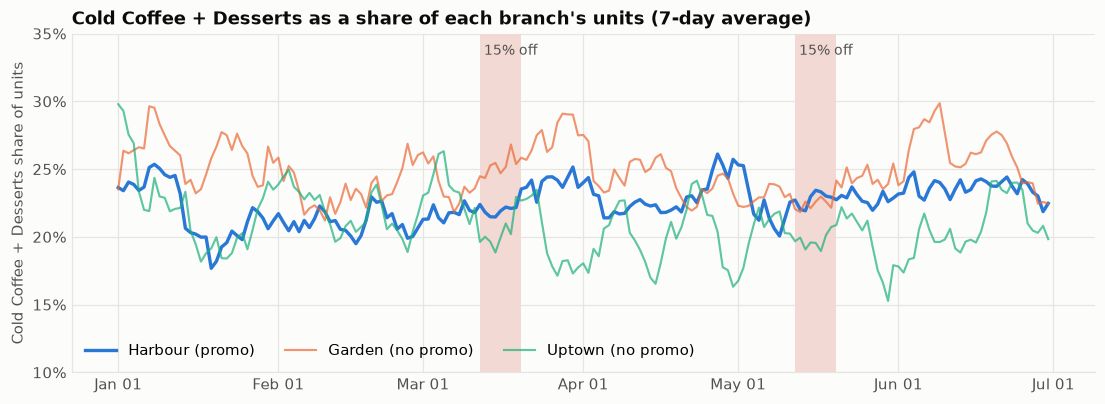

In [10]:
cat_daily = (df.assign(promo_cat=df["Category"].isin(PROMO_CATEGORIES))
             .groupby(["Date", "Branch", "promo_cat"])["Quantity"].sum().unstack().fillna(0))
cat_daily.columns = ["other_units", "promo_cat_units"]
cat_daily["promo_cat_share"] = cat_daily["promo_cat_units"] / (cat_daily["promo_cat_units"] + cat_daily["other_units"])
cat_daily = cat_daily.reset_index()
cat_daily["in_promo"] = False
for a, b in PROMO_WINDOWS:
    cat_daily["in_promo"] |= cat_daily["Date"].between(a, b)

h = cat_daily[cat_daily["Branch"] == PROMO_BRANCH].set_index("Date")
fig, ax = plt.subplots(figsize=(12, 4))
for a, b in PROMO_WINDOWS:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=PROMO_SHADE, lw=0)
    ax.text(pd.Timestamp(a), 0.97, " 15% off", transform=ax.get_xaxis_transform(), color=INK2, va="top", fontsize=9)
for b in BRANCHES:
    s = cat_daily[cat_daily["Branch"] == b].set_index("Date")["promo_cat_share"].rolling(7, center=True, min_periods=3).mean()
    ax.plot(s.index, s.values, color=BRANCH_COLORS[b], lw=2.2 if b == PROMO_BRANCH else 1.4,
            alpha=1 if b == PROMO_BRANCH else 0.7, label=b + (" (promo)" if b == PROMO_BRANCH else " (no promo)"))
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0.1, 0.35)
ax.set_ylabel("Cold Coffee + Desserts share of units")
ax.set_title("Cold Coffee + Desserts as a share of each branch's units (7-day average)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="lower left", ncols=3)
plt.show()

In [11]:
# Difference-in-differences on two measures, using the promo months (March and May) only
m = cat_daily[cat_daily["Date"].dt.month.isin([3, 5])]
did = m.groupby(["Branch", "in_promo"]).agg(units=("promo_cat_units", "mean"), share=("promo_cat_share", "mean")).unstack()
table = pd.DataFrame({
    "promo-category units/day, other days": did[("units", False)],
    "promo-category units/day, promo days": did[("units", True)],
    "change in units": did[("units", True)] / did[("units", False)] - 1,
    "share of units, other days": did[("share", False)],
    "share of units, promo days": did[("share", True)],
    "change in share (points)": (did[("share", True)] - did[("share", False)]) * 100,
}).loc[BRANCHES]
controls = table.loc[[b for b in BRANCHES if b != PROMO_BRANCH]]
did_units = table.loc[PROMO_BRANCH, "change in units"] - controls["change in units"].mean()
did_share = table.loc[PROMO_BRANCH, "change in share (points)"] - controls["change in share (points)"].mean()
print(f"Harbour change minus the average change at the control branches: units {did_units:+.1%}, share {did_share:+.1f} points")
table.style.format({c: "{:.1f}" for c in table.columns if "units/day" in c} |
                   {"change in units": "{:+.1%}", "share of units, other days": "{:.1%}", "share of units, promo days": "{:.1%}",
                    "change in share (points)": "{:+.1f}"})

Harbour change minus the average change at the control branches: units +8.8%, share +1.8 points


,"promo-category units/day, other days","promo-category units/day, promo days",change in units,"share of units, other days","share of units, promo days",change in share (points)
Branch,,,,,,
Harbour,33.5,33.8,+0.7%,22.3%,22.8%,+0.5
Garden,25.0,24.6,-1.5%,24.8%,23.6%,-1.1
Uptown,12.7,10.8,-14.5%,21.1%,19.6%,-1.5


**Is that difference real or luck?** Daily sales bounce around, so any 8-day window will look a bit different from the rest of its month. We run a **placebo test**: we pretend the promo happened in every other possible 8-day window of the six months, compute the same Harbour-vs-controls difference for each fake window, and see where the real promo windows rank.

Real promo Mar 12-19: +1.8 points, bigger than 76% of fake windows
Real promo May 12-19: +0.8 points, bigger than 58% of fake windows


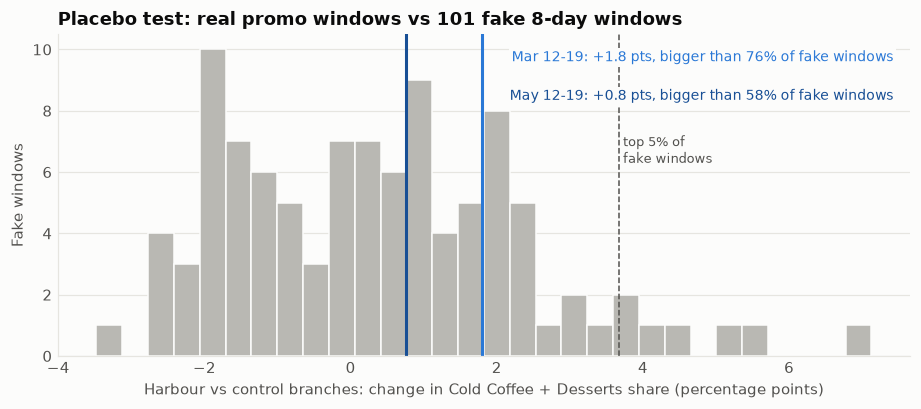

In [12]:
# Daily gap between Harbour's promo-category share and the control branches' average share
ctrl = cat_daily[cat_daily["Branch"] != PROMO_BRANCH].groupby("Date")["promo_cat_share"].mean()
gap = (h["promo_cat_share"] - ctrl).dropna()


def window_effect(start, length=8, context=21):
    """Mean gap inside the window minus the mean gap in the `context` days on each side (excluding real promos)."""
    start = pd.Timestamp(start)
    end = start + pd.Timedelta(days=length - 1)
    inside = gap[start:end]
    around = gap[start - pd.Timedelta(days=context):end + pd.Timedelta(days=context)].drop(inside.index, errors="ignore")
    around = around[~around.index.isin(h.index[h["in_promo"]])]
    return (inside.mean() - around.mean()) * 100


real = {pd.Timestamp(a).strftime("%b %d") + "-" + pd.Timestamp(b).strftime("%d"): window_effect(a) for a, b in PROMO_WINDOWS}
promo_days = set(h.index[h["in_promo"]])
starts = [d for d in gap.index[21:-29] if not any(dd in promo_days for dd in pd.date_range(d, periods=8))]
placebo = pd.Series([window_effect(d) for d in starts], index=starts)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(placebo, bins=30, color=MUTED, edgecolor=SURFACE)
notes = []
for (label, v), c in zip(real.items(), [ACCENT, "#184f95"]):
    ax.axvline(v, color=c, lw=2)
    beat = (placebo < v).mean()
    notes.append((label, v, beat, c))
    print(f"Real promo {label}: {v:+.1f} points, bigger than {beat:.0%} of fake windows")
for i, (label, v, beat, c) in enumerate(notes):
    ax.text(0.98, 0.95 - i * 0.12, f"{label}: {v:+.1f} pts, bigger than {beat:.0%} of fake windows",
            transform=ax.transAxes, ha="right", va="top", color=c, fontsize=9,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
lim95 = placebo.quantile(0.95)
ax.axvline(lim95, color=INK2, lw=1, ls="--")
ax.text(lim95, 0.6, " top 5% of\n fake windows", transform=ax.get_xaxis_transform(), color=INK2, fontsize=8.5)
ax.set_xlabel("Harbour vs control branches: change in Cold Coffee + Desserts share (percentage points)")
ax.set_ylabel("Fake windows")
ax.set_title(f"Placebo test: real promo windows vs {len(placebo)} fake 8-day windows")
ax.grid(axis="x", visible=False)
plt.show()

In [13]:
# Promo orders: did people add a promo item to an order they'd have placed anyway, or buy more of it?
hp = df[(df["Branch"] == PROMO_BRANCH) & df["Date"].dt.month.isin([3, 5])]
hp_orders = hp.groupby("Transaction ID").agg(in_promo=("in_promo", "first"),
                                            has_promo_cat=("Category", lambda s: s.isin(PROMO_CATEGORIES).any()),
                                            items=("Quantity", "sum"), value=(R, "sum"))
basket = hp_orders.groupby("in_promo").agg(orders_per_day=("items", "size"), share_with_promo_item=("has_promo_cat", "mean"),
                                           items_per_order=("items", "mean"), order_value=("value", "mean"))
basket["orders_per_day"] = basket["orders_per_day"] / hp.groupby("in_promo")["Date"].nunique()
basket.index = ["Other days (Mar + May)", "Promo days"]

after = h.copy()
after["window"] = "Other days"
for a, b in PROMO_WINDOWS:
    after.loc[pd.Timestamp(a):pd.Timestamp(b), "window"] = "Promo days"
    after.loc[pd.Timestamp(b) + pd.Timedelta(days=1):pd.Timestamp(b) + pd.Timedelta(days=8), "window"] = "Week after promo"
pull = after.groupby("window")["promo_cat_share"].mean().reindex(["Promo days", "Week after promo", "Other days"])
print("Harbour Cold Coffee + Desserts share of units: " + ", ".join(f"{k} {v:.1%}" for k, v in pull.items()))
basket.style.format({"orders_per_day": "{:.1f}", "share_with_promo_item": "{:.1%}", "items_per_order": "{:.2f}",
                     "order_value": "${:.2f}"}).set_caption("Harbour orders in March and May")

Harbour Cold Coffee + Desserts share of units: Promo days 22.8%, Week after promo 23.4%, Other days 22.4%


,orders_per_day,share_with_promo_item,items_per_order,order_value
Other days (Mar + May),93.6,31.8%,1.59,$9.18
Promo days,93.7,30.6%,1.60,$9.01


**Takeaway**
- **Units barely moved.** Harbour sold about 33.8 Cold Coffee and Dessert units a day during the promo vs 33.5 on other March and May days (+1%). Their share of Harbour's units edged up by about half a point.
- **The controls drifted down** over the same days (Garden -1.5% units, Uptown -15%), so Harbour looks better than the controls: about +9% in units and +1.8 points in share. But the **placebo test says that's normal variation**: the March window beats 76% of fake windows and the May window 58%. A real price effect would need to beat about 95% (the dashed line). Uptown's 15% drop is also just the kind of swing the smallest branch has on any 8-day stretch.
- **Orders didn't change shape.** The share of Harbour orders with a promo item (31% vs 32%), items per order (1.60 vs 1.59) and orders per day (94 both) were the same on promo days. There was also **no dip the week after** (23.4% share, vs 22.4% on other days), so people didn't stock up during the promo and buy less afterwards.
- **The promo gave away about $470** in six months for, at most, a few extra units a day.

## 8. Can we measure price sensitivity at all?

The usual way to measure how much demand reacts to price is to compare sales at different prices. This data barely allows it:
- **Prices never change** within a branch in six months.
- **Across branches, every product is priced with the same ratio** (Garden about 95% and Uptown about 91% of Harbour's price for every one of the 45 products), so there's no product-by-product price difference to learn from.
- Branch differences in demand (Harbour sells far more than Uptown) come from size and location as well as price, so they can't be read as price effects.

In [14]:
p = df.groupby(["Product", "Branch"])["Unit Price (USD)"].first().unstack()[BRANCHES]
ratio = p.div(p["Harbour"], axis=0)
pd.DataFrame({"price vs Harbour: average": ratio.mean(), "lowest product": ratio.min(), "highest product": ratio.max(),
              "price changes over time": df.groupby(["Branch", "Product"])["Unit Price (USD)"].nunique().gt(1)
              .groupby(level=0).sum()}).loc[BRANCHES].style.format(
    {"price vs Harbour: average": "{:.1%}", "lowest product": "{:.1%}", "highest product": "{:.1%}",
     "price changes over time": "{:.0f}"})

,price vs Harbour: average,lowest product,highest product,price changes over time
Branch,,,,
Harbour,100.0%,100.0%,100.0%,0
Garden,95.2%,95.1%,95.3%,0
Uptown,91.4%,91.2%,91.6%,0


**Takeaway:** the only real price variation in the data is the discounts themselves, and those show no measurable effect on demand. That's the best evidence available that **demand here is not price-sensitive**, which supports the team's pitch (align prices up rather than cut them). It's also a limit: we can't say how far prices could rise before customers react, which is why the pitch recommends a controlled price test first.

## 9. What the discounts cost, and what removing them would be worth

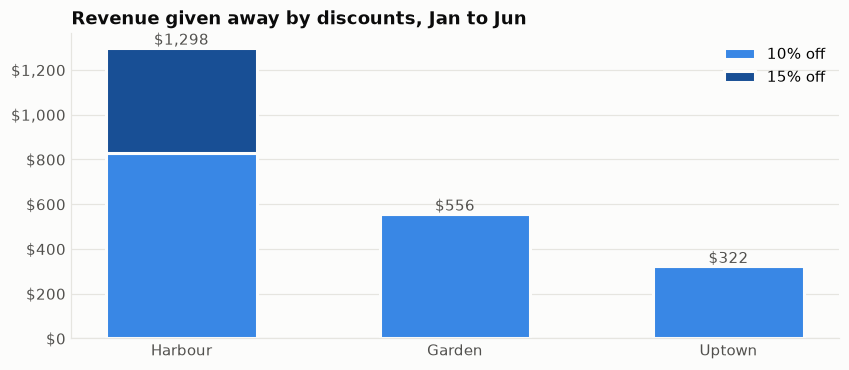

rate,10% off,15% off,total (6 months),per year
Branch,,,,
Harbour,$828,$470,"$1,298","$2,617"
Garden,$556,$0,$556,"$1,121"
Uptown,$322,$0,$322,$650
All branches,"$1,706",$470,"$2,176","$4,388"


In [15]:
cost = df.groupby(["Branch", "rate"])["given_away"].sum().unstack().reindex(columns=["10% off", "15% off"]).fillna(0).loc[BRANCHES]
cost["total (6 months)"] = cost.sum(axis=1)
cost.loc["All branches"] = cost.sum()
cost["per year"] = cost["total (6 months)"] * 365 / df["Date"].nunique()

fig, ax = plt.subplots(figsize=(9, 3.6))
bottom = np.zeros(len(BRANCHES))
for r_ in ["10% off", "15% off"]:
    v = cost.loc[BRANCHES, r_].values
    ax.bar(BRANCHES, v, bottom=bottom, color=RATE_COLORS[r_], label=r_, width=0.55, edgecolor=SURFACE, linewidth=2)
    bottom += v
for i, v in enumerate(bottom):
    ax.text(i, v + 15, f"${v:,.0f}", ha="center", color=INK2)
ax.yaxis.set_major_formatter(usd)
ax.set_title("Revenue given away by discounts, Jan to Jun")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()
cost.style.format("${:,.0f}")

**Takeaway:** discounts cost about **$2,200 in six months, or about $4,400 a year**, almost all of it from the standing 10% discount. Because the evidence in sections 4-7 shows they don't increase quantity, change product choice, bring customers back sooner or lift promo sales, **almost all of that is lost profit** that could be kept, or redirected to something that does work.

## 10. Conclusion and recommendations

| Question | Answer | Evidence |
|---|---|---|
| Who gets the 10% discount? | **Nobody in particular** | About 5.6% of lines everywhere: every branch, product, hour, day, month and customer type; spread across customers matches a random hand-out |
| Do discounts make orders bigger? | **No** | Bigger discounted orders are a counting artifact; a line is equally likely to be discounted in 1-, 2- and 3-line orders, and quantities don't rise |
| Do they change what people buy? | **No** | Same category mix and same average list price with and without the discount |
| Do they bring customers back? | **No** | About 65% back within 30 days either way; next visit no sooner, even within the same customer |
| Did the 15% promo lift demand? | **Not measurably** | Promo-category units +1% at Harbour; vs the control branches the windows beat only 76% and 58% of fake windows (95% needed); no change in orders, no dip afterwards |
| Is demand price-sensitive? | **No sign of it** | The only price variation (the discounts) moves nothing; list prices never change |
| What do discounts cost? | **About $4,400 a year** | Mostly the 10% standing discount |

**Recommendations**
1. **Stop the untargeted 10% discount.** It changes nothing and costs about $3,400 a year on its own.
2. **Don't repeat flat category promotions** like the 15% Cold Coffee + Desserts promo without a clear goal and a way to measure them.
3. **Redirect the budget to what the other analyses support:** rewards for visiting more often (`04_regular_customers`), a matcha + pastry bundle and an add-on at the till (`01_eda`, `06_regulars_products`).
4. **If the team wants to know whether any discount works, test it properly:** pick one offer, run it at one branch for 2-4 weeks with the other branches as controls, decide in advance what counts as success (for example +10% units of the promoted items, or more return visits), and announce it, since the promo here may simply have gone unnoticed.

*The data is synthetic, so the lack of any response to discounts may be partly how it was generated. That's another reason to treat the recommendation to drop discounts as something to confirm with a small test, not a certainty.*